In [2]:
from src import *
import jax.numpy as jnp


In [10]:
def log_target0(x):
    return -0.5 * jnp.sum(x**2)


def log_target1(x, D):
    return -0.5 * jnp.sum((x - D)**2)


def log_target_path_(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def grad_log_target_path(x, D):
    return log_target1(x, D) - log_target0(x)


In [11]:
L = 20  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [21]:
key = jax.random.PRNGKey(42)
Sigma = jnp.eye(2)
mean_init = jnp.array([0.0, 0.0])
Sigma_init = jnp.eye(2)
D = jnp.array([1.0, 1.0])
log_target_path = lambda x, path: log_target_path_(x, path, D)


In [ ]:
mk_grid = tune_km_grid(key,lambda_grid, Sigma, mean_init, Sigma_init, log_target_path, lag=1, nrep=20)
lags = mk_grid["lag"] # we take the lags equal to k_\lambda

mk tuning: 100%|██████████| 21/21 [00:03<00:00,  6.38it/s]


mk tuning: 100%|██████████| 21/21 [00:15<00:00,  1.39it/s]


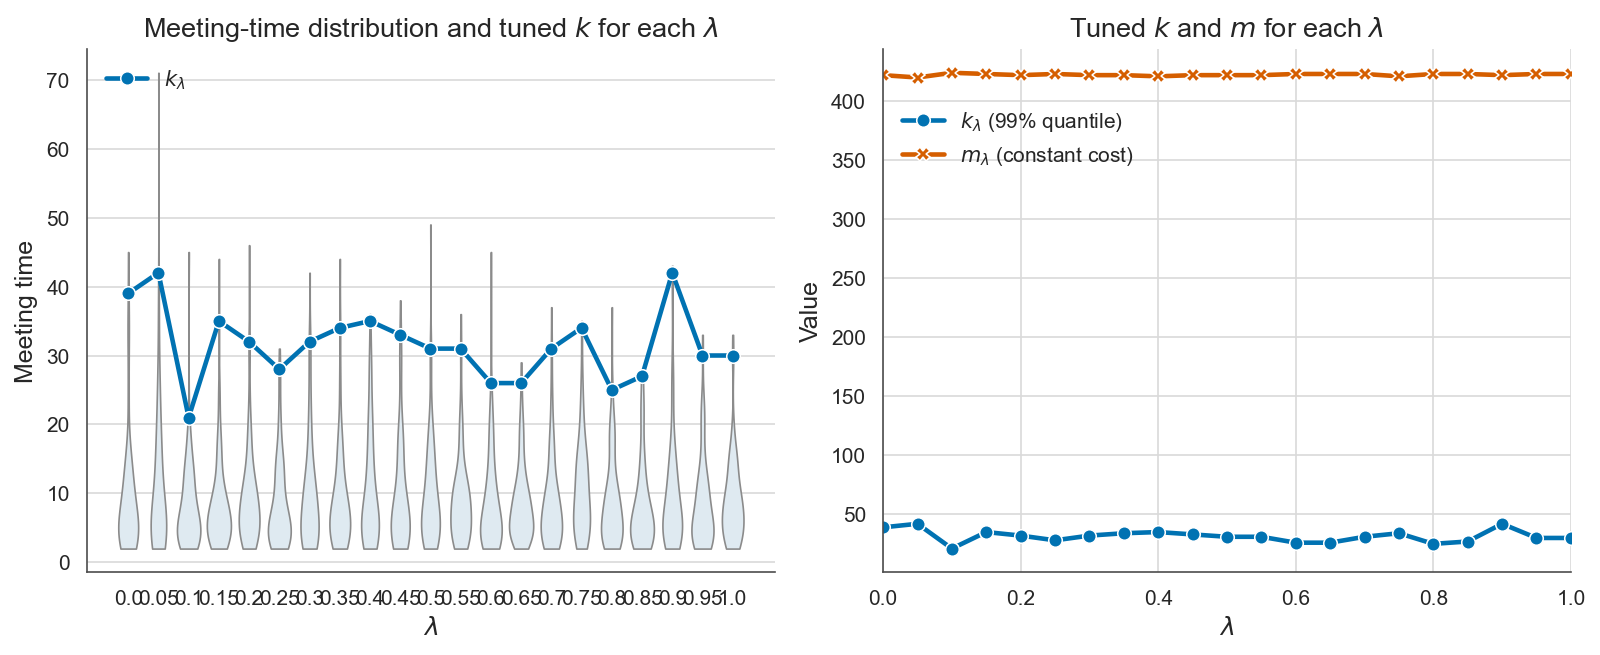

In [ ]:
key, results= plot_km_grid(mk_grid["key"], lambda_grid, Sigma, mean_init, Sigma_init, log_target_path)
